# First look at the data

PM2.5 from the US Embassy station + weather + CAMS, hourly, since Sep 2020.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import FIGURES_DIR
from features import load_hourly, make_daily

plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
df = load_hourly()
df.shape

(53424, 11)

In [3]:
df.head()

,time,pm25,temp,humidity,wind,wind_dir,pressure,precipitation,blh,cams_pm25,cams_pm10
0,2020-09-01 00:00:00,19.0,20.9,65,6.6,209,920.3,0.5,25.0,NaN,NaN
1,2020-09-01 01:00:00,15.0,20.2,61,7.1,246,920.6,0.0,25.0,NaN,NaN
2,2020-09-01 02:00:00,NaN,19.0,65,7.0,215,920.3,0.0,25.0,NaN,NaN
3,2020-09-01 03:00:00,6.0,18.9,65,6.4,207,920.1,0.0,40.0,NaN,NaN
4,2020-09-01 04:00:00,NaN,18.1,68,7.9,227,920.3,0.0,30.0,NaN,NaN


In [4]:
df.describe().round(1)

,time,pm25,temp,humidity,wind,wind_dir,pressure,precipitation,blh,cams_pm25,cams_pm10
count,53424,35261.0,53424.0,53424.0,53424.0,53424.0,53424.0,53424.0,49056.0,36571.0,36571.0
mean,2023-09-18 23:29:59.999999,30.9,11.4,55.9,5.4,180.4,924.1,0.1,280.5,22.8,33.6
min,2020-09-01 00:00:00,0.0,-28.4,7.0,0.0,1.0,905.7,0.0,10.0,0.4,0.6
25%,2022-03-11 11:45:00,9.0,1.7,38.0,3.1,99.0,919.7,0.0,25.0,13.2,19.0
50%,2023-09-18 23:30:00,16.0,12.1,55.0,4.9,166.0,923.6,0.0,55.0,18.7,27.9
75%,2025-03-28 11:15:00,33.0,21.1,73.0,7.1,274.0,928.1,0.0,295.0,28.3,41.7
max,2026-10-05 23:00:00,421.0,41.9,100.0,38.6,360.0,950.3,10.6,4580.0,153.7,347.4
std,NaN,38.8,12.1,21.8,3.2,107.5,6.1,0.3,488.0,14.1,22.3


In [5]:
# how much PM2.5 is missing each year
(df.pm25.isna().groupby(df.time.dt.year).mean() * 100).round(1)

time
2020     24.5
2021     41.7
2022     46.1
2023     16.3
2024      5.4
2025     13.5
2026    100.0
Name: pm25, dtype: float64

In [6]:
df["month"] = df.time.dt.month
df["hour"] = df.time.dt.hour
df["dayofweek"] = df.time.dt.dayofweek
df["season"] = df.month.map(lambda m: "winter" if m in (12, 1, 2) else "summer" if m in (6, 7, 8) else "other")

## PM2.5 by month

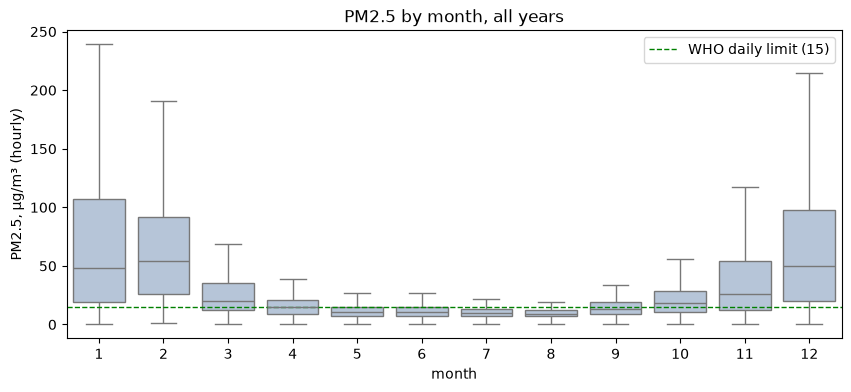

In [7]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="month", y="pm25", showfliers=False, color="lightsteelblue", ax=ax)
ax.axhline(15, color="green", linestyle="--", linewidth=1, label="WHO daily limit (15)")
ax.set_ylabel("PM2.5, µg/m³ (hourly)")
ax.set_title("PM2.5 by month, all years")
ax.legend()
fig.savefig(FIGURES_DIR / "pm25_by_month.png", dpi=120, bbox_inches="tight")

In [8]:
monthly = df.groupby("month").pm25.mean()
print(monthly.round(1))
print("winter / summer:", round(monthly[[12, 1, 2]].mean() / monthly[[6, 7, 8]].mean(), 1))

month
1     70.0
2     62.2
3     26.0
4     16.6
5     11.8
6     12.0
7     10.7
8     10.1
9     14.7
10    21.8
11    38.2
12    67.0
Name: pm25, dtype: float64
winter / summer: 6.1


## Hour of the day, winter vs summer

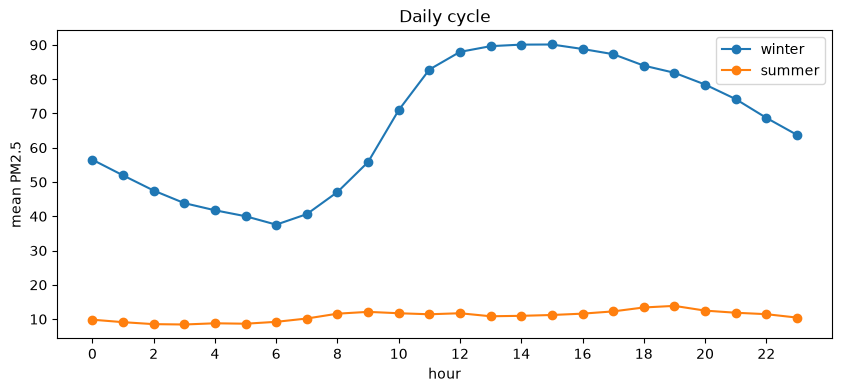

In [9]:
fig, ax = plt.subplots()
for season in ["winter", "summer"]:
    part = df[df.season == season]
    part.groupby("hour").pm25.mean().plot(ax=ax, marker="o", label=season)
ax.set_xticks(range(0, 24, 2))
ax.set_ylabel("mean PM2.5")
ax.set_title("Daily cycle")
ax.legend()
fig.savefig(FIGURES_DIR / "daily_cycle.png", dpi=120, bbox_inches="tight")

## Weekdays vs weekends
If traffic matters a lot, weekends should be cleaner.

In [10]:
heating = df[df.month.isin([11, 12, 1, 2, 3])]
heating.groupby("dayofweek").pm25.mean().round(1)

dayofweek
0    53.5
1    51.4
2    52.2
3    52.0
4    55.0
5    52.2
6    50.2
Name: pm25, dtype: float64

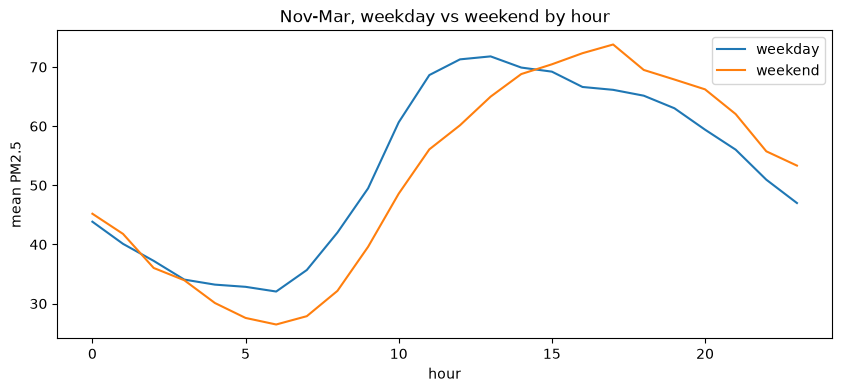

In [11]:
fig, ax = plt.subplots()
heating.assign(weekend=heating.dayofweek >= 5).groupby(["hour", "weekend"]).pm25.mean().unstack().plot(ax=ax)
ax.set_title("Nov-Mar, weekday vs weekend by hour")
ax.set_ylabel("mean PM2.5")
ax.legend(["weekday", "weekend"])

## Top 10 dirtiest days

In [12]:
daily = make_daily(df)
daily.sort_values("pm25", ascending=False).head(10)[
    ["date", "pm25", "pm25_max", "temp", "wind", "blh", "blh_night", "pm25_hours"]
].set_index("date").round(1)

,pm25,pm25_max,temp,wind,blh,blh_night,pm25_hours
date,,,,,,,
2020-12-24,222.0,337.0,-9.8,8.5,34.2,24.6,24
2020-12-25,204.1,277.0,-5.6,7.6,29.0,22.1,23
2023-01-16,204.1,342.0,-13.8,9.3,24.0,22.1,18
2021-01-29,195.5,258.0,-6.7,7.3,29.0,20.0,24
2020-12-18,185.1,284.0,-6.4,3.6,26.5,20.0,24
2020-12-28,183.3,229.0,-9.3,10.4,33.5,24.6,23
2021-01-09,180.2,396.0,-10.1,3.6,58.3,23.8,24
2023-01-28,177.0,272.0,-8.0,9.1,28.3,25.4,24
2021-01-08,170.0,224.0,-11.3,4.9,71.9,33.3,24
